# Trabajo Final. KNN vs LSTM

Materia: Métodos para el Análisis de Datos I

Alumna: Pilar Maiztegui

---
Este trabajo se basa en el artículo _Deep Learning vs Machine Learning for Intrusion Detection in Computer Networks: A Comparative Study_ (Ali et al., 2025, Applied Sciences, 15(4), 1903), en el cual se comparan modelos de aprendizaje automático clásicos contra modelos de aprendizaje profundo para la detección de intrusiones en redes de computadoras, utilizando el dataset CICIDS-2017.



Importemos el dataset indicado.

In [1]:
import pandas as pd
import glob

archivos = glob.glob(r"C:\Users\tetep\OneDrive\Documentos\UNS\Metodos para el Analisis de Datos I\MachineLearningCVE\*.csv")

df = pd.concat(
    [pd.read_csv(archivo) for archivo in archivos],
    ignore_index=True
)

Primero, chequeamos que el tamaño del dataset coincida con el indicado en el trabajo. 

In [2]:
df.shape

(2830743, 79)

Ahora sí, empezamos con el preprocesamiento. Primero, miramos si hay filas duplicadas. 

In [3]:
duplicados=df.duplicated()
cantidad_duplicados=duplicados.sum()
print(f"Total de filas duplicadas: {cantidad_duplicados}   ")

Total de filas duplicadas: 308381   


Se encuentran 308.381 filas duplicadas para eliminar.

In [4]:
df = df.drop_duplicates()
print(f"Total de filas duplicadas: {df.duplicated().sum()}")

Total de filas duplicadas: 0


In [5]:
df.shape

(2522362, 79)

Con los duplicados ya eliminados, nos interesa hallar los datos faltantes para luego tratarlos. 

In [6]:
faltantes = df.isnull().sum()
faltantes[faltantes > 0]

Flow Bytes/s    353
dtype: int64

In [7]:
df['Flow Bytes/s'].describe()

c:\Users\tetep\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    2.522009e+06
mean              inf
std               NaN
min     -2.610000e+08
25%      1.194510e+02
50%      3.722028e+03
75%      1.079162e+05
max               inf
Name: Flow Bytes/s, dtype: float64

Notemos que la media de Flow Bytes/s, columna donde están todos los datos faltantes, es infinita. Por lo que, propongo primero eliminar las filas que contengan datos infinitos, tal como indicaba el siguiente paso, y luego completar los datos faltantes con la media no infinita. 

In [8]:
import numpy as np
infinitos = np.isinf(df.select_dtypes(include=np.number)).sum()
infinitos[infinitos > 0]

Flow Bytes/s       1211
 Flow Packets/s    1564
dtype: int64

Una vez identificados, eliminamos las filas que contengan +inf o -inf, tal como se indicaba.

In [9]:
df = df[~np.isinf(df.select_dtypes(include=np.number)).any(axis=1)]
# Para comprobar:
np.isinf(df.select_dtypes(include=np.number)).sum().sum()

np.int64(0)

Ahora, volvamos a calcular la media de Flow Bytes/s para poder reemplazar en los datos faltantes. Elegimos reemplazar los valores faltantes con la media porque es simple y efectiva para datos numéricos, y minimiza el impacto en la distribución de los datos.

In [10]:
media =df['Flow Bytes/s'].mean()
print(f"Media de 'Flow Bytes/s': {media}")

Media de 'Flow Bytes/s': 1410706.951183008


In [11]:
df['Flow Bytes/s']=df['Flow Bytes/s'].fillna(media)

# Comprobemos que no hay valores nulos en la columna 'Flow Bytes/s'
print(f"Valores nulos en 'Flow Bytes/s': {df['Flow Bytes/s'].isnull().sum()}")

Valores nulos en 'Flow Bytes/s': 0


Nos interesa simplificar la clasificación de la columna Label, usando el siguiente mapeo:
- Si contiene "Web Attack", lo clasificamos como "Web Attack".
- Si contiene "DoS", lo clasificamos como "DoS".
- Si contiene "DDoS", lo clasificamos como "DDoS".
- Si contiene "Bot", lo clasificamos como "Bot".
- "BENIGN" lo dejamos como está.
- El resto lo agrupamos en "Other".

Miremos las etiquetas antes de modificarlas:


In [12]:
df.columns = df.columns.str.strip()
df.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

In [13]:
df['Label'] = df['Label'].str.strip()
df['Label'].value_counts()

Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [14]:
df.loc[df['Label'].str.contains('Web Attack', na=False), 'Label'] = 'Web Attack'

df.loc[df['Label'].str.contains('DoS', na=False) &
       ~df['Label'].str.contains('DDoS', na=False), 'Label'] = 'DoS'

df.loc[df['Label'].str.contains('DDoS', na=False), 'Label'] = 'DDoS'

df.loc[df['Label'].str.contains('PortScan', na=False), 'Label'] = 'PortScan'

df.loc[df['Label'].str.contains('Bot', na=False), 'Label'] = 'Bot'

df.loc[df['Label'].str.contains('BENIGN', na=False), 'Label'] = 'BENIGN'

categorias = ['Web Attack', 'DoS', 'DDoS', 'PortScan', 'Bot', 'BENIGN']

df.loc[~df['Label'].isin(categorias), 'Label'] = 'Other'

#Para verificar:
df['Label'].value_counts()

Label
BENIGN        2095057
DoS            193745
DDoS           128014
PortScan        90694
Other            9197
Web Attack       2143
Bot              1948
Name: count, dtype: int64

Esto nos permite reducir la complejidad de la clasificación y para asegurar que cada categoría tenga suficientes ejemplos para que el modelo aprenda. 

Comenzamos con el entrenamiento.

In [15]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Label'])
y = df['Label']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Ahora estandarizamos (media 0, desvío 1) a las columnas numéricas.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
import pandas as pd

comprobacion = pd.DataFrame({
    'Media': X_train_scaled.mean(axis=0),
    'Desvio': X_train_scaled.std(axis=0)
}, index=X_train.columns)

comprobacion

,Media,Desvio
Destination Port,-1.251513e-17,1.0
Flow Duration,3.410654e-18,1.0
Total Fwd Packets,-6.764933e-19,1.0
Total Backward Packets,-1.127489e-18,1.0
Total Length of Fwd Packets,9.019910e-19,1.0
...,...,...
Active Min,-1.313524e-17,1.0
Idle Mean,-8.529453e-17,1.0
Idle Std,6.990431e-18,1.0
Idle Max,-3.774269e-17,1.0


Observamos al comprobar que el desvío es 1 para todas las columnas, y la media nos da números muy cercanos a 0, tal como buscabamos. 

Como la distribución del dataset estaba muy desbalanceada, con BENIGN dominando ampliamente, aplicamos SMOTE (Synthetic Minority Over-sampling Technique) sobre el conjunto de entrenamiento. Esta técnnica genera muestras sinteticas para las clases menos representadas. Se hace para que el modelo aprenda de un grupo mas diverso de ejemplos, lo que mejora su capacidad de  generalizar, en especial para la detección de las clases pequeñas. 

In [18]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

In [19]:
print("Distribución de clases antes de SMOTE:")
print(y_train.value_counts())   
print("\nDistribución de clases después de SMOTE:")
print(y_train_smote.value_counts())

Distribución de clases antes de SMOTE:
Label
BENIGN        1676045
DoS            154996
DDoS           102411
PortScan        72555
Other            7358
Web Attack       1714
Bot              1559
Name: count, dtype: int64

Distribución de clases después de SMOTE:
Label
BENIGN        1676045
DoS           1676045
PortScan      1676045
DDoS          1676045
Other         1676045
Web Attack    1676045
Bot           1676045
Name: count, dtype: int64


Calculamos la matriz de correlación entre features y eliminamos aquellas con correlación absoluta mayor a 0.85 con otra feature. 

In [20]:
import numpy as np

corr = X_train.corr().abs()

triangulo_superior = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)
columnas_eliminar = [
    columna for columna in triangulo_superior.columns
    if (triangulo_superior[columna] > 0.85).any()
]

columnas_eliminar

['Total Backward Packets',
 'Total Length of Bwd Packets',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow IAT Max',
 'Fwd IAT Total',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Min',
 'Fwd Packets/s',
 'Max Packet Length',
 'Packet Length Mean',
 'Packet Length Std',
 'Packet Length Variance',
 'SYN Flag Count',
 'CWE Flag Count',
 'ECE Flag Count',
 'Average Packet Size',
 'Avg Fwd Segment Size',
 'Avg Bwd Segment Size',
 'Fwd Header Length.1',
 'Subflow Fwd Packets',
 'Subflow Fwd Bytes',
 'Subflow Bwd Packets',
 'Subflow Bwd Bytes',
 'act_data_pkt_fwd',
 'Active Min',
 'Idle Mean',
 'Idle Max',
 'Idle Min']

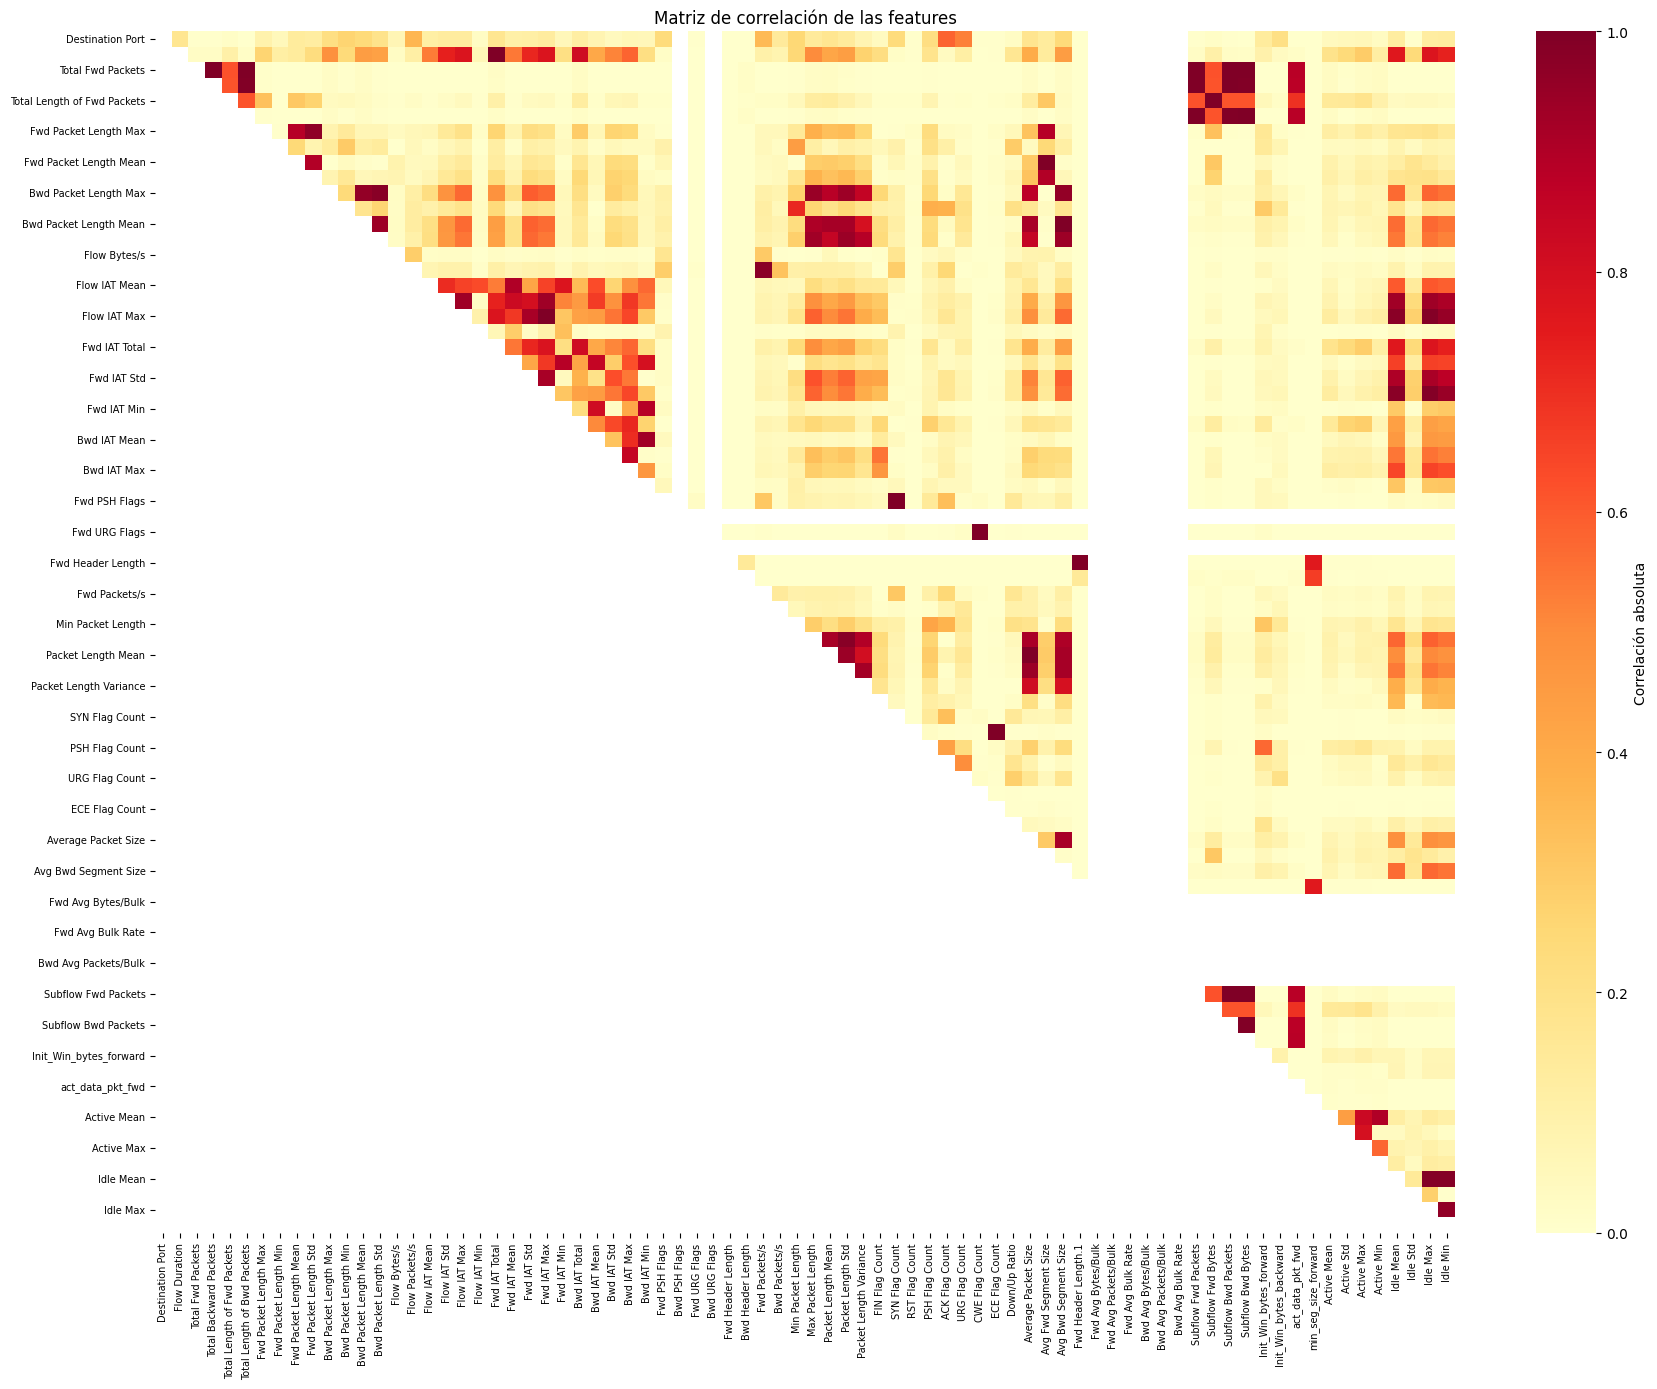

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ocultamos el triángulo inferior y la diagonal
mascara = np.tril(
    np.ones_like(corr, dtype=bool)
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr,
    mask=mascara,
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Correlación absoluta"}
)

plt.title("Matriz de correlación de las features")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

Estas son las columnas que el código propone eliminar por tener una correlación mayor a 0.85. Veamos con que otra columna se relaciona:

In [22]:
for columna in columnas_eliminar:
    correlacionadas = triangulo_superior.index[
        triangulo_superior[columna] > 0.85
    ]
    
    for otra in correlacionadas:
        print(columna, "-", otra, ":", triangulo_superior.loc[otra, columna])

Total Backward Packets - Total Fwd Packets : 0.9990037704142726
Total Length of Bwd Packets - Total Fwd Packets : 0.9970093016274344
Total Length of Bwd Packets - Total Backward Packets : 0.994098410235358
Fwd Packet Length Mean - Fwd Packet Length Max : 0.8890275179317735
Fwd Packet Length Std - Fwd Packet Length Max : 0.9686822343974067
Fwd Packet Length Std - Fwd Packet Length Mean : 0.8976124228057732
Bwd Packet Length Mean - Bwd Packet Length Max : 0.9581823912574747
Bwd Packet Length Std - Bwd Packet Length Max : 0.9824656252675702
Bwd Packet Length Std - Bwd Packet Length Mean : 0.9406669652962388
Flow IAT Max - Flow IAT Std : 0.9374509408304854
Fwd IAT Total - Flow Duration : 0.9985226695883999
Fwd IAT Mean - Flow IAT Mean : 0.9013157493921288
Fwd IAT Std - Flow IAT Max : 0.9149704935581933
Fwd IAT Max - Flow IAT Std : 0.9354445245625489
Fwd IAT Max - Flow IAT Max : 0.9980463043568589
Fwd IAT Max - Fwd IAT Std : 0.9172529378625194
Fwd IAT Min - Fwd IAT Mean : 0.8857899352361273

In [23]:
print("Variables originales:", X_train.shape[1])
print("Variables a eliminar:", len(columnas_eliminar))
print("Variables restantes:", X_train.shape[1] - len(columnas_eliminar))

Variables originales: 78
Variables a eliminar: 34
Variables restantes: 44


Ahora sí, eliminamos las features necesarias:

In [24]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_train_scaled = X_train_scaled.drop(columns=columnas_eliminar)
X_test_scaled = X_test_scaled.drop(columns=columnas_eliminar)
print("Columnas de entrenamiento:", X_train_scaled.shape[1])
print("Columnas de test:", X_test_scaled.shape[1])

Columnas de entrenamiento: 44
Columnas de test: 44


Como aplicamos SMOTE antes de la selección de features, el conjunto de entrenamiento balanceado todavía contiene todas las variables. Por eso, eliminamos de X_train_smote las mismas columnas, para que queden las mismas 44 variables. 

In [25]:
X_train_smote = pd.DataFrame(
    X_train_smote,
    columns=X_train.columns
)
X_train_smote = X_train_smote.drop(columns=columnas_eliminar)
X_train_smote.shape

(11732315, 44)

Acá damos por terminado el preprocesamiento. 

# _KNN: K-Nearest Neighbors._ 

El método de KNN es un algoritmo de clasificación basado en memoria, es decir, que conserva las observaciones del conjunto de entrenamiento. KNN asume que los puntos cercanos en el espacio pertenecen a una misma clase. 

Dado un $x_0$ nuevo que queremos clasificar, buscamos las $k$ observaciones más cercanas a él en el conjunto de entrenamiento y se le asigna la clase mayoritaria de esos $k$ vecinos.

Para simplicidad, asumimos que los datos son valores reales y usamos la distancia Euclídea, esto es, si $x_{(i)}$ es una observación del conjunto de entrenamiento y $x_0$ la observación que queremos $d_{(i)}=||x_{(i)}-x_0||$, aunque se podría optar por otras como la Manhattan o la Minkowski.

Como la clasificación es en base a distancias, se suele estandarizar cada variable para que tengan media 0 y varianza 1, y así evitar que las medidas en mayores escalas tengan demasiada influencia sobre las distancias. 

El hiperparámetro $k$ determina la cantidad de vecinos a considerar para realizar la clasificación. La elección de este hiperparámetro es clave al aplicar el método. Si eligieramos $k=1$, el modelo memoriza cada dato y generamos una frontera muy irregular. Esta elección presenta bajo sesgo pero alta varianza. Si eligieramos un $k$ demasiado grande, la frontera se vuelve más suave, el modelo ignora detalles locales, aumentando el sesgo global. 

Una limitación importante de KNN es la maldición de la dimensionalidad. En espacios de alta dimensión, los vecinos más cercanos pueden estar muy lejos, causando sesgo y empeorando la clasificación. Esto resulta especialmente relevante al trabajar con datasets con muchas variables, como el de este trabajo, lo que motiva a eliminar las variables redundantes antes de aplicar el método. 

En resumen, las fortalezas de KNN son su simplicidad y su fácil interpretación. Pero como debilidades, además del problema de las dimensiones, puede ser computacionalmente costoso clasificar nuevas observaciones, pues es necesario calcular sus distancias respecto a los datos que ya teníamos.


Ahora, apliquemos el método. Necesitamos hacer validación cruzada para elegir nuestro $k$, pero como tenemos más de 11 millones de filas, sería poco práctico hacerla sobre todo el conjunto. Por eso, tomamos una muestra más pequeña, de $100.000$ observaciones. Sobre esta muestra, probamos algunos valores de k y elegimos el que sea más conveniente. 

In [26]:
from sklearn.model_selection import StratifiedShuffleSplit

muestreo = StratifiedShuffleSplit(
    n_splits=1,
    train_size=100000,
    random_state=42
)

for indices_muestra, _ in muestreo.split(X_train_smote, y_train_smote):
    X_knn_muestra = X_train_smote.iloc[indices_muestra]
    y_knn_muestra = y_train_smote.iloc[indices_muestra]

X_knn_muestra.shape
y_knn_muestra.value_counts()

Label
Bot           14286
DDoS          14286
Other         14286
PortScan      14286
BENIGN        14286
Web Attack    14285
DoS           14285
Name: count, dtype: int64

Notemos como cada clase de la muestra representa aproximadamente $1/7$ de la muestra. Esto es porque aplicamos SMOTE previamente.

In [27]:
from sklearn.model_selection import StratifiedKFold

validacion_cruzada = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

busqueda_k = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [5, 7, 9, 11]
    },
    scoring="f1_macro",
    cv=validacion_cruzada,
    n_jobs=2,
    verbose=2
)


busqueda_k.fit(X_knn_muestra, y_knn_muestra)
for k, f1 in zip(
    busqueda_k.cv_results_["param_n_neighbors"],
    busqueda_k.cv_results_["mean_test_score"]
):
    print(f"k = {k}: F1 macro promedio = {f1:.4f}")


Fitting 3 folds for each of 4 candidates, totalling 12 fits
k = 5: F1 macro promedio = 0.9893
k = 7: F1 macro promedio = 0.9881
k = 9: F1 macro promedio = 0.9870
k = 11: F1 macro promedio = 0.9860


In [ ]:
print("Mejor valor de k:", busqueda_k.best_params_["n_neighbors"])
print("Mejor F1 macro promedio:", busqueda_k.best_score_)

Mejor valor de k: 5
Mejor F1 macro promedio: 0.9893483561871529


Para la elección de $k$ probamos distintos valores impares entre 5 y 11, evitando valores pequeños que produzcan fronteras demasiado irregulares y con mayor varianza. Entre los valores considerados, $k=5$ resultó el mejor para el modelo final.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_final = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    n_jobs=2
)

knn_final.fit(X_knn_muestra, y_knn_muestra)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",2


In [ ]:
y_pred_knn = knn_final.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

f1_macro_knn = f1_score(
    y_test, y_pred_knn,
    average="macro"
)

f1_ponderado_knn = f1_score(
    y_test, y_pred_knn,
    average="weighted"
)

precision_knn = precision_score(
    y_test, y_pred_knn,
    average="weighted",
    zero_division=0
)

recall_knn = recall_score(
    y_test, y_pred_knn,
    average="weighted",
    zero_division=0
)


accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("Accuracy:", accuracy_knn)
print("F1 macro:", f1_macro_knn)
print("F1 ponderado:", f1_ponderado_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)

Accuracy: 0.9641046493176769
F1 macro: 0.7091519754281297
F1 ponderado: 0.9712051978492205
Precision: 0.9820238617911157
Recall: 0.9641046493176769


Decidimos usar una muestra de 100.000 observaciones para aplicar KNN en lugar de hacerlo sobre todo el conjunto de entrenamiento obtenido luego de aplicar SMOTE por su alto costo computacional.

Se entrenó el modelo KNN utilizando las 100.000 observaciones de la muestra luego evaluamos sobre el conjunto del test original, que no había sido modificado por SMOTE. 

De esta manera, obtuvimos:
- Accuracy: 0.9641
- F1 Macro: 0.7092
- F1 Ponderado: 0.9712
- Precisión: 0.9820
- Recall: 0.9641

Los resultados reportados en _Ali et. Al. (2025)_ eran:
- Accuracy: 99.36%
- F1 Macro: 97.62%
- F1 Ponderado: 99%

Todas nuestras métricas fueron inferiores a las del trabajo referenciado, sobretodo el F1 Score (Macro). Esto puede deberse a que elegimos trabajar con una muestra y no con todas las observaciones obtenidas luego de SMOTE. Aunque la estratificación mantuvo la distribución de las clases, la reducción de las observaciones implica que KNN tiene menos datos para encontrar los vecinos más cercanos. 

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn, digits=4))

              precision    recall  f1-score   support

      BENIGN     0.9996    0.9576    0.9781    419012
         Bot     0.0656    0.9949    0.1230       389
        DDoS     0.9884    0.9987    0.9935     25603
         DoS     0.9384    0.9943    0.9656     38749
       Other     0.6082    0.9902    0.7536      1839
    PortScan     0.7377    0.9973    0.8481     18139
  Web Attack     0.1781    0.9953    0.3022       429

    accuracy                         0.9641    504160
   macro avg     0.6451    0.9898    0.7092    504160
weighted avg     0.9820    0.9641    0.9712    504160



# _LSTM: Long Short-Term Memory_

El método de LSTM es un tipo de RNN (red neuronal recurrente) con compuertas. Estas RNN se basan en la idea de crear caminos en el tiempo que tengan derivadas que no exploten ni desaparezcan, conectando con pesos que pueden cambiar en cada paso. Además, permite que la red acumule información durante ciertos períodos y aprenda cuando es momento de olvidarla. 

Lo especial del LSTM es la **célula de memoria** que tienen una recurrencia interna además de las recurrencias externas de la RNN. Cada célula tiene la misma cantidad de entradas y salidas que la red, pero tiene más parámetros y un sistema de compuertas que controlan el flujo de información. 

El peso del auto-loop esta controlado por una **puerta de olvido** $f_i^{(t)}$ (siendo el paso temporal $t$ y la célula $i$), asiganando un peso entre 0 y 1.  Sea $x^{(t)}$ el vector de entrada, $h^{(t)}$ el vector de capa oculta que contiene las salidas de todas las células de LSTM, y $b^f$, $U^f$, $W^f$ el sesgo, los pesos de entradas y los pesos de salida para las puertas de olvido, respectivamente: 

$$
f_i^{(t)} =
\sigma \left(
b_i^f
+ \sum_j U_{i,j}^f x_j^{(t)}
+ \sum_j W_{i,j}^f h_j^{(t-1)}
\right)
$$

La **puerta de entrada** controla el ingreso de nueva información a la célula y así, la red determina si esto resulta relevante como para ser almacenada.

La **puerta de salida** controla qué parte de la célula se usa para generar la salida correspondiente al paso actual.

En resumen, en cada paso el LSTM recibe nueva información, con información que ya tenía del paso anterior. Mediante a sus puertas, aprende a decidir qué información conservar, olvidar y usar de salida. 



Apliquemos el método. Para entrenar la red, usamos la misma muestra que usamos para KNN, así comparamos ambos modelos en mismas condiciones.

Convirtamos las etiquetas a números. 

In [ ]:
X_lstm_muestra = X_knn_muestra.copy()
y_lstm_muestra = y_knn_muestra.copy()

Transformemos las etiquetas a números, así la red puede trabajar con ellas:

In [ ]:
from sklearn.preprocessing import LabelEncoder

codificador_lstm = LabelEncoder()

# Aprende la correspondencia y transforma las etiquetas de entrenamiento
y_lstm_codificado = codificador_lstm.fit_transform(y_lstm_muestra)

# Usa la misma correspondencia para transformar test
y_test_lstm_codificado = codificador_lstm.transform(y_test)

for numero, clase in enumerate(codificador_lstm.classes_):
    print(numero, "->", clase)

0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS
4 -> Other
5 -> PortScan
6 -> Web Attack


Separamos la muestra:

In [ ]:
from sklearn.model_selection import train_test_split

X_lstm_train, X_lstm_val, y_lstm_train, y_lstm_val = train_test_split(
    X_lstm_muestra,
    y_lstm_codificado,
    test_size=0.2,
    random_state=42,
    stratify=y_lstm_codificado
)
print("Entrenamiento:", X_lstm_train.shape, y_lstm_train.shape)
print("Validación:", X_lstm_val.shape, y_lstm_val.shape)

Entrenamiento: (80000, 44) (80000,)
Validación: (20000, 44) (20000,)


Reformamos a X pues LSTM espera datos tridimensionales:

In [ ]:
import numpy as np

X_lstm_train_3d = X_lstm_train.to_numpy(dtype=np.float32).reshape(
    X_lstm_train.shape[0],
    X_lstm_train.shape[1],
    1
)

X_lstm_val_3d = X_lstm_val.to_numpy(dtype=np.float32).reshape(
    X_lstm_val.shape[0],
    X_lstm_val.shape[1],
    1
)

print("Entrenamiento:", X_lstm_train_3d.shape)
print("Validación:", X_lstm_val_3d.shape)

Entrenamiento: (80000, 44, 1)
Validación: (20000, 44, 1)


In [ ]:
%pip install torch keras

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 18.5 MB/s  0:00:00
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ---------------------------------------- 3.2/3.2 MB 31.5 MB/s  0:00:00
   ---------------------------------------- 0.0/581.4 kB ? eta -:--:--
   ---------------------------------------- 581.4/581.4 kB 18.7 MB/s  0:00:00

   ---- ----------------------------------- 1/9 [optree]
   ---- ----------------------------------- 1/9 [optree]
   ---- ----------------------------------- 1/9 [optree]
   ------------- -------------------------- 3/9 [mdurl]
   ----------------- ---------------------- 4/9 [h5py]
   ----------------- ---------------------- 4/9 [h5py]
   ----------------- ---------------------- 4/9 [h5py]
   ----------------- ---------------------- 4/9 [h5py]
   ----------------- ---------------------- 4/9 [h5py]
   ----------------- ---------------------- 4/9 [h5py]
   ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os

os.environ["KERAS_BACKEND"] = "torch"

In [ ]:
import keras

from keras.models import Sequential
from keras.layers import Input, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping

cantidad_clases = len(codificador_lstm.classes_)

modelo_lstm = Sequential([
    Input(shape=(44, 1)),
    
    LSTM(64),
    
    Dropout(0.2),
    
    Dense(32, activation="relu"),
    
    Dense(cantidad_clases, activation="softmax")
])

modelo_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,207 (75.03 KB)

 Trainable params: 19,207 (75.03 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_lstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
parada_temprana = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

historial_lstm = modelo_lstm.fit(
    X_lstm_train_3d,
    y_lstm_train,
    validation_data=(X_lstm_val_3d, y_lstm_val),
    epochs=15,
    batch_size=512,
    callbacks=[parada_temprana],
    verbose=1
)

Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 48s 305ms/step - accuracy: 0.5430 - loss: 1.2849 - val_accuracy: 0.7484 - val_loss: 0.7284
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 335ms/step - accuracy: 0.8325 - loss: 0.5652 - val_accuracy: 0.8561 - val_loss: 0.4813
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 48s 303ms/step - accuracy: 0.8759 - loss: 0.4135 - val_accuracy: 0.8980 - val_loss: 0.3218
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 330ms/step - accuracy: 0.8967 - loss: 0.3424 - val_accuracy: 0.9191 - val_loss: 0.2778
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 48s 308ms/step - accuracy: 0.9173 - loss: 0.2760 - val_accuracy: 0.9289 - val_loss: 0.2391
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 48s 307ms/step - accuracy: 0.9234 - loss: 0.2548 - val_accuracy: 0.9348 - val_loss: 0.2158
Epoch 7/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 324ms/step - accuracy: 0.9107 - loss: 0.2970 - val_accuracy: 0.9294 - val_loss: 0.2094
Epoch 8/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 64s 410ms/step - accuracy: 0.9335 - loss: 0

Como <<val_loss>> sigue bajando, seguimos entrenando

In [ ]:
parada_temprana_extra = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

historial_lstm_extra = modelo_lstm.fit(
    X_lstm_train_3d,
    y_lstm_train,
    validation_data=(X_lstm_val_3d, y_lstm_val),
    initial_epoch=15,
    epochs=30,
    batch_size=512,
    callbacks=[parada_temprana_extra],
    verbose=1
)

Epoch 16/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 49s 315ms/step - accuracy: 0.9561 - loss: 0.1460 - val_accuracy: 0.9613 - val_loss: 0.1252
Epoch 17/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 325ms/step - accuracy: 0.9244 - loss: 0.2578 - val_accuracy: 0.9097 - val_loss: 0.2785
Epoch 18/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 327ms/step - accuracy: 0.9406 - loss: 0.1998 - val_accuracy: 0.9424 - val_loss: 0.1675


El mejor paso fue el 16. Ahora predecimos:

In [ ]:
X_lstm_test_3d = X_test_scaled.to_numpy(
    dtype=np.float32
).reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

X_lstm_test_3d.shape

(504160, 44, 1)

In [ ]:
probabilidades_lstm = modelo_lstm.predict(
    X_lstm_test_3d,
    batch_size=512,
    verbose=1
)

y_pred_lstm_codificado = np.argmax(
    probabilidades_lstm,
    axis=1
)

985/985 ━━━━━━━━━━━━━━━━━━━━ 47s 47ms/step


Calculamos las metricas:

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_lstm = accuracy_score(
    y_test_lstm_codificado,
    y_pred_lstm_codificado
)

f1_macro_lstm = f1_score(
    y_test_lstm_codificado,
    y_pred_lstm_codificado,
    average="macro"
)

f1_ponderado_lstm = f1_score(
    y_test_lstm_codificado,
    y_pred_lstm_codificado,
    average="weighted"
)

precision_lstm = precision_score(
    y_test_lstm_codificado,
    y_pred_lstm_codificado,
    average="weighted",
    zero_division=0
)

recall_lstm = recall_score(
    y_test_lstm_codificado,
    y_pred_lstm_codificado,
    average="weighted",
    zero_division=0
)

print("Accuracy:", accuracy_lstm)
print("F1 macro:", f1_macro_lstm)
print("F1 ponderado:", f1_ponderado_lstm)
print("Precision:", precision_lstm)
print("Recall:", recall_lstm)

Accuracy: 0.8676094890510949
F1 macro: 0.5723542102590732
F1 ponderado: 0.8975070554527199
Precision: 0.9473132126853429
Recall: 0.8676094890510949


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_lstm_codificado,
        y_pred_lstm_codificado,
        target_names=codificador_lstm.classes_,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      BENIGN     0.9974    0.8447    0.9147    419012
         Bot     0.0195    0.9923    0.0382       389
        DDoS     0.7309    0.9885    0.8404     25603
         DoS     0.7229    0.9689    0.8280     38749
       Other     0.3415    0.9679    0.5048      1839
    PortScan     0.6790    0.9931    0.8065     18139
  Web Attack     0.0383    0.9953    0.0738       429

    accuracy                         0.8676    504160
   macro avg     0.5042    0.9644    0.5724    504160
weighted avg     0.9473    0.8676    0.8975    504160



Para entrenar nuestro modelo, utilizamos la misma muestra de 100.000 observaciones que usamos para entrenar KNN. El 80% fueron destinadas al entrenamiento, y el resto, a la validación. Terminamos evaluando sobre el conjunto de test original. 

De esta manera, obtuvimos:
- Accuracy: 0.8676
- F1 Macro: 0.5724
- F1 Ponderado: 0.8975
- Precisión: 0.9473
- Recall: 0.8676

En _Ali et. Al. (2025)_ se reportó:
- Accuracy: 98.00%
- F1 Macro: 84.00%
- F1 Ponderado: 98.00%

De nuevo, nuestras métricas dieron por debajo de las del trabajo asignado. Al analizarlas por clase, vemos que el recall es alto para todas las categorías, por lo que estamos encontrando un gran porcentaje de los ataques verdaderos. Sin embargo, por la precisión baja en las clases más pequeñas, entendemos que estamos encontrando muchos falsos positivos.

Esta diferencia puede deberse a que, como en KNN, elegimos entrenar con una muestra de 100.000 datos (por el costo computacional de usar un conjunto más grande) con clases balanceadas, y luego predecimos sobre el dataset original. 

# _Análisis Crítico._

En KNN obtuvimos una accuracy de aproximadamente el 96% y en LSTM, esta fue cerca del 87%. Esta métrica nos indica que porcentaje de las observaciones clasificamos correctamente. En KNN, aun que fue un poco inferior a lo que se obtuvo en _Ali et. Al_, es un resultado muy bueno. En LSTM, si bien es más bajo, no es un mal resultado. 

En términos de F1, una métrica que relaciona la precisión y el recall, podemos observar algunas cosas. F1 Macro calcula el F1 de todas las clases y luego los promedia, dandole la misma importancia a todas las clases. Notemos que este nos dió bajo en ambos métodos, sobretodo en LSTM, y esto vimos que fue porque en las clases minoritarias teníamos muchos falsos positivos. Sin embargo, el F1 ponderado fue alto en ambos métodos, destacando en KNN que fue del 97%. Eso es porque, esta métrica le da más importancia a las clases más grandes, y ahí obtuvimos mejores resultados al predecir. 

Por lo tanto, nuestras predicciones fueron mejores para KNN que para LSTM. 



Tal como leemos en el artículo asignado, LSTM funciona especialmente bien para analizar tráfico de red secuencial y para detectar patrones de ataque dependientes del tiempo. Sin embargo, las observaciones de CICIDS-2017 son  características ya calculadas del tráfico y no una verdadera secuencia temporal, por lo que es posible que LSTM no aproveche su principal ventaja. 

Por otro lado, la representación tabular podría beneficiar a KNN, que compara las observaciones según su cercanía (su parecido), lo que podría explicar porque obtuvimos mejores resultados con este método. 

El desbalance en las clases es una dificultad para ambos modelos. Algunas categorías están mucho menos representadas que otras y, aunque aplicamos SMOTE para crear datos sintéticos y "emparejar" las clases durante el entrenamiento, vimos que siguen siendo problemáticas en los resultados. 

Entonces, ¿para qué tipo de datos LSTM superaría a KNN? Como dijimos antes, LSTM es particularmente apropiada para patrones dependientes del tiempo. Si los ataques se pudieran identificar a partir de una sucesión temporal de hechos, probablemente este método sería más adecuado y detecte las dependencias temporales, cosa para lo que KNN no está diseñado. 

Al hacer este tipo de estudios, nos resulta interesante hablar del costo computacional y qué tan eficiente es cada método. Notemos que tuvimos que trabajar con una muestra de 100.000 observaciones y de todas formas, algunos pasos llevaron bastante tiempo. 

Por eso, aunque un modelo sea un poco más preciso que otro, puede no ser la mejor opción ya que puede necesitar más recursos computacionales o tiempo.

Observemos en nuestro caso, que el entrenamiento de KNN fue rápido. Pero la elección del hiperparámetro $k$ y predecir, que conlleva calcular las distancias de todos los datos con una nueva observación, pueden ser bastante costosos. 

Al contrario, entrenar LSTM fue mucho más lento, pero el momento de predecir es más ágil. 

# _¿Cuándo gana el aprendizaje profundo?_

Buscabamos un paper en el que LSTM sea mejor que KNN. Trabajamos con _"A comparative study of machine learning algorithms for fall detection in technology-based healthcare system: analyzing SVM, KNN, decision tree, random forest, LSTM, and CNN"_  
.

El objetivo está puesto en detectar caídas, lo que resulta importante en el sector de salud, sobretodo pensando en los adultos mayores ya que puede tener consecuencias graves. Gracias al avance en la tecnología de los dispositivos portátiles, es posible monitorear condiciones físicas en tiempo real y detectar caídas. 

La dificultad está en la precisión y eficacia de los algoritmos usados, que les cuesta diferenciar entre caídas reales y actividades normales, como caminar o sentarse.

En este artículo, se trabaja con el dataset de Kaggle Smartphone Human Fall Dataset, que incluye variables como aceleración máxima, velocidad angular, velocidad angular luego de la caída, aceleración lineal luego de la caída, entre otras.  

En el procesamiento de datos, se eliminaron los duplicados y los valores faltantes y se normalizaron las variables. El  dataset tenía 1428 observaciones de entrenamiento, que representaban el 70% de la muestra,  y 573 de prueba. Se hizo validación cruzada de 10 capas para evitar sobreajuste.

Luego del entrenamiento y prueba de los algoritmos, se vieron los siguientes resultados:
- KNN: Accuracy de 87%, Recall de 80%, Presición de 85% y F1-Score de 81%.
- LSTM: Accuracy de 92%, Recall de 92%, Presición de 91% y F1-Score de 92%.

Entonces, ¿por qué en este caso es mejor LSTM? Los datos provienen de sensores que registran movimientos de una persona, y las caídas pueden incluir cambios repentinos de aceleración y velocidad. Estas combinaciones pueden crear patrones complejos, más díficiles de reconocer para algoritmos como KNN. Pero favorece a los modelos de aprendizaje profundo como LSTM, que además, si recibiera las mediciones en orden temporal, podría aprender como evoluciona el movimiento antes, durante y después de la caída. 

KNN funciona mejor para clasificar observaciones que se distinguen por sus características. En este caso, una caída podría tener un valor parecido a una actividad normal en alguna variable, aunque el patrón sea distinto. 

Para concluir, podemos observar que para problemas cuyas clases están mas bien distinguidas y sin patrones complejos, conviene usar KNN. En cambio, para secuencias temporales o patrones complejos, es preferible usar LSTM. Otro factor para la elección del modelo es el tiempo de entrenamiento y predicción (Recordemos que entrenar con KNN es rápido, pero predecir con LSTM es más rápido que predecir con KNN) y la cantidad de datos. 